# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'M&Ms',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Nate Garcia', 'github': 'NateG-10'},
        {'name': 'Mohamed Hassan', 'github': 'Moehassan09'},
        {'name': 'Mouad Tazka', 'github': 'Mouad-Tazka'},
    ],
    'repo_url': 'https://github.com/NateG-10/F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/NateG-10/F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Nate Garcia',           # nice to have
    'meeting_time': 'Wednesdays and Thursdays at 8:00 PM Eastern Time',
    'five_worst_problems': [
    'Exact duplicate transaction rows can inflate sales totals.',
    'Store IDs have inconsistent capitalization, spaces, and separators.',
    'Timestamps use mixed formats, and 884 cleaned rows have missing timestamps.',
    'Unit prices are stored as text, sometimes with dollar signs or spaces.',
    'Multiple SKUs describe Strawberry Pop-Tarts, including different package sizes.'
],
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
import subprocess

REPO_PATH = '/Users/nategarcia/Desktop/DS2002/F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

529fd27 adding Charter


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [3]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Find the team repository
REPO_NAME = "F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad"

def find_repo_root():
    here = Path.cwd()

    folders = [
        here,
        *here.parents,
        Path("/content") / REPO_NAME
    ]

    for folder in folders:
        if (
                (folder / "CHARTER.md").is_file()
                and (folder / "data" / "walmart_transactions.csv").is_file()
        ):
            return folder

    raise FileNotFoundError(
        "Team repository not found. Open this notebook "
        "from your cloned repo or clone the repo into Colab."
    )


REPO_ROOT = find_repo_root()

def find_data(filename):
    path = REPO_ROOT / "data" / filename

    if not path.is_file():
        raise FileNotFoundError(filename)

    return path


# Load the transaction and store files
raw = pd.read_csv(
    find_data("walmart_transactions.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

stores_raw = pd.read_csv(
    find_data("store_locations.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

print("Original transactions:", len(raw))
print("Store reference rows:", len(stores_raw))


# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(
            r"^FL[-_\s]*(\d+)$",
            r"FL-\1",
            regex=True
        )
    )


# Parse different timestamp formats
def clean_dates(series):
    formats = [
        "%Y-%m-%dT%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%Y-%m-%d %H:%M",
        "%m/%d/%Y %H:%M",
        "%m/%d/%Y %H:%M:%S",
        "%m-%d-%Y %H:%M:%S",
        "%m-%d-%Y %H:%M",
        "%d-%b-%Y %H:%M",
        "%d-%b-%Y %H:%M:%S"
    ]

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns]"
    )

    for fmt in formats:
        parsed = pd.to_datetime(
            series,
            format=fmt,
            errors="coerce"
        )

        result = result.fillna(parsed)

    return result


# Standardize category labels
CATEGORY_ALIASES = {
    "Alcoholic Beverages": "Alcohol",
    "Baby Products": "Baby",
    "Breakfast Foods": "Breakfast",
    "Emergency Supplies": "Emergency",
    "Games & Entertainment": "Entertainment",
    "Groceries": "Grocery",
    "Health & Wellness": "Health",
    "Household Essentials": "Household"
}


def clean_category(series):
    return (
        series.astype("string")
        .str.strip()
        .str.title()
        .replace(CATEGORY_ALIASES)
    )


# Main transaction cleaning function
def clean_transactions(df):
    cleaned = df.copy()
    log = []

    # 1. Remove exact duplicate rows
    before = len(cleaned)
    cleaned = cleaned.drop_duplicates().copy()

    log.append({
        "dataset": "transactions",
        "step": "Remove exact duplicates",
        "before": before,
        "after": len(cleaned),
        "affected": before - len(cleaned)
    })

    # Helper for logging steps that do not remove rows
    def log_step(step, affected):
        log.append({
            "dataset": "transactions",
            "step": step,
            "before": len(cleaned),
            "after": len(cleaned),
            "affected": int(affected)
        })

    # 2. Standardize store IDs
    cleaned["store_id_clean"] = clean_store_id(
        cleaned["store_id"]
    )

    changed_stores = (
            cleaned["store_id"].astype("string")
            != cleaned["store_id_clean"]
    ).fillna(False).sum()

    log_step("Standardize store IDs", changed_stores)

    # 3. Parse timestamps
    cleaned["timestamp_clean"] = clean_dates(
        cleaned["timestamp"]
    )

    # Create daily dates for the weather join
    cleaned["date"] = (
        cleaned["timestamp_clean"].dt.normalize()
    )

    log_step(
        "Parse nonmissing timestamps",
        cleaned["timestamp_clean"].notna().sum()
    )

    log_step(
        "Flag missing / unparseable timestamps",
        cleaned["timestamp_clean"].isna().sum()
    )

    log_step(
        "Create daily date keys",
        cleaned["date"].notna().sum()
    )

    # 4. Convert prices into numeric values
    price_text = cleaned["unit_price"].astype("string")

    formatted_prices = price_text.str.contains(
        r"\$|^\s|\s$",
        regex=True,
        na=False
    ).sum()

    cleaned["unit_price_clean"] = pd.to_numeric(
        price_text
        .str.strip()
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    log_step(
        "Clean formatted unit prices",
        formatted_prices
    )

    log_step(
        "Flag missing/unparseable unit prices",
        cleaned["unit_price_clean"].isna().sum()
    )

    # 5. Convert quantities and flag possible returns
    cleaned["quantity_clean"] = pd.to_numeric(
        cleaned["quantity"],
        errors="coerce"
    )

    cleaned["possible_return"] = (
            cleaned["quantity_clean"] < 0
    )

    log_step(
        "Flag negative quantities",
        cleaned["possible_return"].sum()
    )

    log_step(
        "Flag missing/unparseable quantities",
        cleaned["quantity_clean"].isna().sum()
    )

    # 6. Standardize SKUs
    cleaned["sku_clean"] = (
        cleaned["sku"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    changed_skus = (
            cleaned["sku"].astype("string")
            != cleaned["sku_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize SKU formatting",
        changed_skus
    )

    # 7. Standardize categories
    cleaned["category_clean"] = clean_category(
        cleaned["category"]
    )

    changed_categories = (
            cleaned["category"].astype("string")
            != cleaned["category_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize category formatting and aliases",
        changed_categories
    )

    return cleaned, pd.DataFrame(log)


Original transactions: 25562
Store reference rows: 14


In [11]:
# Run the cleaning function
clean, decision_log = clean_transactions(raw)


# Standardize the store reference data
stores_clean = stores_raw.copy()

stores_clean["store_id_clean"] = clean_store_id(
    stores_clean["store_id"]
)

# Check that store aliases do not have conflicting details
conflicts = stores_clean.groupby("store_id_clean")[
    ["city", "state", "latitude", "longitude"]
].nunique(dropna=True)

assert not conflicts.gt(1).any().any(), (
    "Conflicting store information was found."
)

# Remove duplicate store aliases
stores_clean = stores_clean.drop_duplicates(
    subset="store_id_clean"
).copy()

# Add the store-reference decision to the log
store_log = pd.DataFrame([{
    "dataset": "store_locations",
    "step": "Consolidate duplicate store ID aliases",
    "before": len(stores_raw),
    "after": len(stores_clean),
    "affected": len(stores_raw) - len(stores_clean)
}])

decision_log = pd.concat(
    [decision_log, store_log],
    ignore_index=True
)


# Show cleaning results
print("Original transactions:", len(raw))
print("Cleaned transactions:", len(clean))
print("Rows removed:", len(raw) - len(clean))

print("Unique cleaned stores:",
      clean["store_id_clean"].nunique())

print("Original category labels:",
      raw["category"].nunique())

print("Cleaned category labels:",
      clean["category_clean"].nunique())

print("\nCleaning decision log:")
display(decision_log)


# Verify that the correct number of duplicates was removed
assert len(clean) == (
        len(raw) - raw.duplicated().sum()
)

assert not clean.duplicated(
    subset=raw.columns.tolist()
).any()

# Check numeric columns
assert clean["unit_price_clean"].notna().all(), (
    "Some prices are missing or could not be converted."
)

assert clean["quantity_clean"].notna().all(), (
    "Some quantities are missing or could not be converted."
)

# Confirm stores match the reference file
assert clean["store_id_clean"].isin(
    stores_clean["store_id_clean"]
).all(), "Some store IDs did not match."

# Check timestamp parsing
assert (
        clean["timestamp_clean"].isna().sum()
        == clean["timestamp"].isna().sum()
), "Some nonmissing timestamps failed to parse."

# Check date format for weather analysis
assert pd.api.types.is_datetime64_any_dtype(
    clean["date"]
)

assert clean.loc[
    clean["date"].notna(), "date"
].dt.hour.eq(0).all()

print("\nAll initial cleaning checks passed!")


# Check the transaction timeline
daily_orders = (
    clean.dropna(subset=["date"])
    .groupby("date")
    .size()
)

print("\nFirst sales date:",
      daily_orders.index.min().date())

print("Last sales date:",
      daily_orders.index.max().date())

print("Peak daily order date:",
      daily_orders.idxmax().date())

print("Peak daily transaction records:",
      int(daily_orders.max()))

Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


## 2. Cleaning Decision Log

I started a decision log to keep track of what we cleaned, how many rows were affected, and why we made each change. My main goal was to avoid deleting data unless there was a clear reason to.

For example, I removed exact duplicates because they could cause us to count the same transaction more than once. However, I kept negative quantities and missing timestamps because we don't know for sure if those are errors.

The cleaning function generates a table showing the row counts before and after each step, along with how many records were affected. This allows us to verify our decisions using the actual dataset.

| Problem | Decision | Reason |
|---|---|---|
| Duplicate transactions | Remove exact duplicates | Counting the same transaction twice could inflate sales. |
| Inconsistent store IDs | Standardize capitalization, spaces, and separators | Different versions of the same store ID could cause incorrect joins. |
| Duplicate store records | Consolidate matching store ID aliases after checking their information | Prevents the store join from duplicating transaction records. |
| Missing or mixed-format timestamps | Parse the dates, keep missing values, and create daily date keys | We shouldn't guess when purchases happened. Daily analysis can exclude undated rows. |
| Prices stored as text | Remove dollar signs and extra spaces, then convert to numeric | Numeric prices are necessary for revenue calculations. |
| Negative quantities | Keep and flag them as possible returns or errors | We shouldn't assume every negative quantity is incorrect or automatically delete it. |
| Inconsistent SKUs | Standardize formatting while preserving original SKU values | This prepares the data for product consolidation without losing the original codes. |
| Inconsistent categories | Standardize capitalization and known category aliases | Different labels for the same category could distort category-level demand analysis. |

### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [5]:
# Load the product catalog
products = pd.read_csv(
    find_data("product_catalog.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

# Standardize product SKUs and categories
products["sku_clean"] = (
    products["sku"]
    .astype("string")
    .str.strip()
    .str.upper()
)

products["category_clean"] = clean_category(
    products["category"]
)

# Each catalog SKU should have one reference record
assert products["sku_clean"].is_unique, (
    "Duplicate cleaned SKUs found in product catalog."
)


# Start SKU mapping with Strawberry Pop-Tarts
pop_tarts_mapping = pd.DataFrame({
    "sku_clean": [
        "PT-12",
        "SKU#459812",
        "POPTART-STRAW",
        "PT_STRAWBERRY"
    ],
    "product_family": [
                          "Strawberry Pop-Tarts"
                      ] * 4
})


# Preserve information from the product catalog
pop_tarts_mapping = pop_tarts_mapping.merge(
    products[[
        "sku_clean",
        "product_name",
        "package_size",
        "category_clean"
    ]],
    on="sku_clean",
    how="left",
    validate="one_to_one"
)


# Check that all four SKUs were matched
assert len(pop_tarts_mapping) == 4

assert pop_tarts_mapping["sku_clean"].is_unique

assert pop_tarts_mapping["product_name"].notna().all(), (
    "Some Pop-Tarts SKUs were not found in the catalog."
)


# Extract numerical package counts
# Examples: "4-pack", "4pk", and "6 pack"
pop_tarts_mapping["pack_count"] = pd.to_numeric(
    pop_tarts_mapping["package_size"]
    .astype("string")
    .str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

assert pop_tarts_mapping["pack_count"].notna().all()


# Build a provisional catalog mapping
# Unmapped SKUs remain separate for now
family_lookup = pop_tarts_mapping.set_index(
    "sku_clean"
)["product_family"]

catalog_progress = products.copy()

catalog_progress["canonical_product"] = (
    catalog_progress["sku_clean"]
    .map(family_lookup)
    .fillna(catalog_progress["sku_clean"])
)


# Find the largest consolidated group
group_sizes = (
    catalog_progress
    .groupby("canonical_product")["sku_clean"]
    .nunique()
    .sort_values(ascending=False)
)


# Show SKU mapping progress
print("Starting distinct catalog SKUs:",
      products["sku_clean"].nunique())

print("SKUs mapped into Pop-Tarts family:",
      pop_tarts_mapping["sku_clean"].nunique())

print("Explicitly mapped product families:",
      pop_tarts_mapping["product_family"].nunique())

print("Provisional canonical product groups:",
      catalog_progress["canonical_product"].nunique())

print("Largest consolidated group:",
      group_sizes.idxmax())

print("SKUs in largest group:",
      int(group_sizes.max()))

print("Remaining unmapped SKUs:",
      products["sku_clean"].nunique()
      - pop_tarts_mapping["sku_clean"].nunique())


print("\nPop-Tarts SKU mapping:")
display(pop_tarts_mapping)

print("\nPackage-size differences present:",
      pop_tarts_mapping["pack_count"].nunique() > 1)

Starting distinct catalog SKUs: 45
SKUs mapped into Pop-Tarts family: 4
Explicitly mapped product families: 1
Provisional canonical product groups: 42
Largest consolidated group: Strawberry Pop-Tarts
SKUs in largest group: 4
Remaining unmapped SKUs: 41

Pop-Tarts SKU mapping:


,sku_clean,product_family,product_name,package_size,category_clean,pack_count
0,PT-12,Strawberry Pop-Tarts,pop-tarts strawberry,4-pack,Breakfast,4
1,SKU#459812,Strawberry Pop-Tarts,Strawberry Pop-Tart,4pk,Breakfast,4
2,POPTART-STRAW,Strawberry Pop-Tarts,Pop-Tarts Strawberry,6 pack,Breakfast,6
3,PT_STRAWBERRY,Strawberry Pop-Tarts,pop-tarts strawberry,4 pack,Breakfast,4



Package-size differences present: True


In [6]:
# Get positive transactions for the mapped Pop-Tarts SKUs
pop_sales = clean.loc[
    clean["sku_clean"].isin(
        pop_tarts_mapping["sku_clean"]
    )
    & clean["quantity_clean"].gt(0)
    ].copy()


# Calculate positive reported quantities by SKU
sku_totals = (
    pop_sales
    .groupby("sku_clean")["quantity_clean"]
    .sum()
    .reindex(
        pop_tarts_mapping["sku_clean"],
        fill_value=0
    )
    .sort_values(ascending=False)
)

print("Positive reported quantities by SKU:")
display(
    sku_totals.to_frame("quantity_sold")
)

print("Combined reported quantity:",
      int(sku_totals.sum()))

print("Number of mapped SKUs:",
      len(sku_totals))


# Separate dated and undated sales
pop_dated = pop_sales.dropna(
    subset=["date"]
).copy()

undated_quantity = pop_sales.loc[
    pop_sales["date"].isna(),
    "quantity_clean"
].sum()

print("\nQuantity with valid sales dates:",
      int(pop_dated["quantity_clean"].sum()))

print("Quantity with missing dates:",
      int(undated_quantity))


# Create the initial daily SKU comparison
daily_fragmented = pop_dated.pivot_table(
    index="date",
    columns="sku_clean",
    values="quantity_clean",
    aggfunc="sum",
    fill_value=0
)

# Keep all four mapped SKU columns
daily_fragmented = daily_fragmented.reindex(
    columns=pop_tarts_mapping["sku_clean"],
    fill_value=0
)

# Combine the four SKU quantities by day
daily_fragmented[
    "Strawberry Pop-Tarts (combined)"
] = daily_fragmented.sum(axis=1)


print("\nInitial daily sales comparison:")
display(daily_fragmented.head(10))

print(
    "\nNote: Quantities are reported SKU units, "
    "not adjusted for different package sizes."
)

Positive reported quantities by SKU:


,quantity_sold
sku_clean,
PT-12,1381
POPTART-STRAW,1300
PT_STRAWBERRY,1262
SKU#459812,1255


Combined reported quantity: 5198
Number of mapped SKUs: 4

Quantity with valid sales dates: 5005
Quantity with missing dates: 193

Initial daily sales comparison:


sku_clean,PT-12,SKU#459812,POPTART-STRAW,PT_STRAWBERRY,Strawberry Pop-Tarts (combined)
date,,,,,
2024-09-01,16,15,24,18,73
2024-09-02,34,17,14,14,79
2024-09-03,28,8,12,22,70
2024-09-04,17,15,19,13,64
2024-09-05,33,43,31,44,151
2024-09-06,33,51,33,40,157
2024-09-07,48,50,41,38,177
2024-09-08,35,43,43,43,164
2024-09-09,32,28,30,60,150



Note: Quantities are reported SKU units, not adjusted for different package sizes.


In [7]:
# Verify the Pop-Tarts mapping
assert pop_tarts_mapping["sku_clean"].nunique() == 4

assert (
        pop_tarts_mapping["product_family"].nunique() == 1
)

# Consolidation should not change total reported quantity
assert sku_totals.sum() == (
    pop_sales["quantity_clean"].sum()
)

# Daily consolidation should preserve dated quantities
assert (
        daily_fragmented[
            "Strawberry Pop-Tarts (combined)"
        ].sum()
        == pop_dated["quantity_clean"].sum()
)

# Dated and undated quantities must reconcile
assert (
        pop_dated["quantity_clean"].sum()
        + undated_quantity
        == pop_sales["quantity_clean"].sum()
)


# Verify that transaction SKUs exist in the catalog
catalog_reference = products[[
    "sku_clean",
    "category_clean"
]].rename(columns={
    "category_clean": "catalog_category_clean"
})

validated = clean.merge(
    catalog_reference,
    on="sku_clean",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(validated) == len(clean), (
    "Catalog join changed the number of transactions."
)

unmatched_skus = (
        validated["_merge"] == "left_only"
).sum()

category_mismatches = (
    validated["category_clean"]
    .ne(validated["catalog_category_clean"])
    .fillna(False)
).sum()

print("Transactions with unmatched SKUs:",
      int(unmatched_skus))

print("Transaction/category disagreements:",
      int(category_mismatches))

assert unmatched_skus == 0, (
    "Some transaction SKUs are missing from the catalog."
)

if category_mismatches > 0:
    print(
        "Review category disagreements before "
        "using categories in the final analysis."
    )


print("\nAll SKU mapping checks passed!")


# Save the decision log and starter mapping
output_path = REPO_ROOT / "data"

decision_log.to_csv(
    output_path / "decision_log_week1.csv",
    index=False
)

pop_tarts_mapping.to_csv(
    output_path / "sku_mapping_DRAFT.csv",
    index=False
)

print("Decision log saved.")
print("SKU mapping saved.")

Transactions with unmatched SKUs: 0
Transaction/category disagreements: 0

All SKU mapping checks passed!
Decision log saved.
SKU mapping saved.


### Initial SKU Mapping Findings

I started with 45 distinct SKUs in the product catalog and mapped four Strawberry Pop-Tarts SKUs into one proposed product family. With the other SKUs still treated separately, this leaves 42 provisional product groups. This isn't the final consolidation since the remaining products still need to be reviewed.

I also calculated the reported positive quantities for each of the four Pop-Tarts SKUs and combined them to show the total quantity associated with that product family. This helps show why SKU consolidation matters, since looking at just one code could underestimate demand for the overall product.

For the daily analysis, I excluded transactions with missing timestamps because we can't determine which day those purchases occurred. I kept those transactions in the overall cleaned dataset so they aren't lost entirely.

One limitation is that the four Pop-Tarts SKUs don't all have the same package size. Three describe four-packs and one describes a six-pack, so combining their quantities directly doesn't mean we're comparing identical amounts of product. I kept the package information in the mapping table so we can account for these differences later.

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [8]:
import time
import requests

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'daily': 'precipitation_sum,windspeed_10m_max', 'timezone': 'America/New_York'}
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if response.status_code in RETRY_STATUSES:
            if attempt == tries:
                response.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        frame = pd.DataFrame(response.json()['daily']).rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame
    raise RuntimeError('Weather request ended without returning data.')

start_date = clean['date'].min().strftime('%Y-%m-%d')
end_date = clean['date'].max().strftime('%Y-%m-%d')
weather = daily_weather(start_date, end_date)
daily_orders = clean.dropna(subset=['date']).groupby('date').size().rename('orders').reset_index()
weather_merged = daily_orders.merge(weather, on='date', how='left', indicator=True)
assert len(weather_merged) == len(daily_orders), 'Weather join changed the sales-day row count.'
assert weather_merged['orders'].sum() == daily_orders['orders'].sum(), 'Weather join changed total orders.'
print(f'Weather API rows: {len(weather)} | source: {weather["source"].iloc[0]}')
print(f'Sales days matched to weather: {(weather_merged["_merge"] == "both").sum()} of {len(daily_orders)}')
print(f'Sales days missing weather: {(weather_merged["_merge"] == "left_only").sum()}')
print('Timezone: America/New_York; sales timestamps are timezone-naive, so both series are keyed to local calendar dates.')
display(weather.head())

Weather API rows: 30 | source: open-meteo
Sales days matched to weather: 30 of 30
Sales days missing weather: 0
Timezone: America/New_York; sales timestamps are timezone-naive, so both series are keyed to local calendar dates.


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

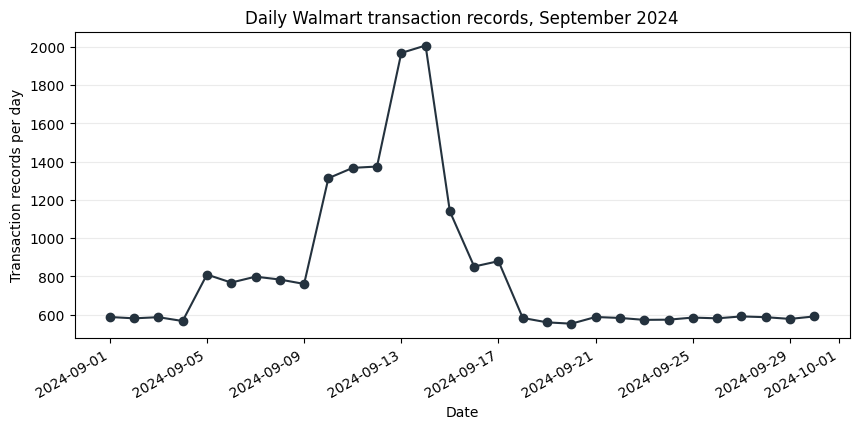

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_orders['date'], daily_orders['orders'], marker='o', color='#24323E')
ax.set_title('Daily Walmart transaction records, September 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Transaction records per day')
ax.grid(axis='y', alpha=0.25)
fig.autofmt_xdate()
plt.show()

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [10]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),
    'charter_committed': True,
}

progress = {
    'rows_after_cleaning': len(clean),
    'decisions_logged': len(decision_log),
    'canonical_products': catalog_progress["canonical_product"].nunique(),
    'weather_api_rows': len(weather),
    'notebook_runs_clean': True,  # after successful Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 12
  done - canonical_products = 42
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."


**b)** What are you doing about it this week? Name who is doing it and by when.

Biggest risk: The SKU mapping currently consolidates only 4 of 45 catalog SKUs, and those mapped SKUs include both 4-packs and a 6-pack. If we treat reported quantities as directly comparable, Q2 demand totals—and potentially Q5 inventory comparisons—could be misleading.

Plan, with an owner and a date: Mouad, the Q2 and Q5 owner, will expand the mapping and document package-size differences by Wednesday, October 28. Nate will review the proposed groups before they are used in the analysis. At the team meeting, we’ll agree how to handle unresolved SKUs and package sizes before finalizing those comparisons.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | in progress -- peak and baseline evidence found; full question analysis still needed | _nate_ |
| Q2 SKU consolidation | _in progress -- one product family mapped; most SKUs still need revivew_ | _mouad_ |
| Q3 weather correlation | _draft answer -- API join and correlation/lag anlaysis are documented; findings have limits_ | _mohamed_ |
| Q4 store and geography | _not started_ | _nate_ |
| Q5 signal or artifact | _not started_ | _mouad_ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.